In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os

#for dirname, _, filenames in os.walk('/kaggle/input'):
 #   for filename in filenames:
  #      print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import sys
print("Python version:", sys.version)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.cuda.amp import autocast, GradScaler
from torchvision import transforms

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import NearestNeighbors

import os
import pickle
from tqdm import tqdm  # Progress bar için

print("\n✓ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Python version: 3.11.13 (main, Jun  4 2025, 08:57:29) [GCC 11.4.0]

✓ All libraries imported successfully!
PyTorch version: 2.6.0+cu124
CUDA available: True
GPU: Tesla P100-PCIE-16GB


In [3]:


DATASET_INPUT_PATH = '/kaggle/input/fashion-product-images-dataset/fashion-dataset'
IMAGE_DIR = os.path.join(DATASET_INPUT_PATH, 'images')

WORKING_DIR = '/kaggle/working/'
MODEL_DIR = os.path.join(WORKING_DIR, 'models')
RESULTS_DIR = os.path.join(WORKING_DIR, 'results')

# Klasörleri oluştur
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Paths configured:")
print(f"  Input images: {IMAGE_DIR}")
print(f"  Model output: {MODEL_DIR}")
print(f"  Results output: {RESULTS_DIR}")

# Dataset kontrolü
image_files = [f for f in os.listdir(IMAGE_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]
print(f"\n✓ Found {len(image_files)} images in dataset")

Paths configured:
  Input images: /kaggle/input/fashion-product-images-dataset/fashion-dataset/images
  Model output: /kaggle/working/models
  Results output: /kaggle/working/results

✓ Found 44441 images in dataset


In [4]:
class FashionDataset(Dataset):
    def __init__(self, image_dir, transform=None, max_images=None):
        """
        Args:
            image_dir: Görüntülerin bulunduğu klasör
            transform: Transformasyonlar
            max_images: Maksimum görüntü sayısı (test için)
        """
        self.image_dir = image_dir
        self.transform = transform
        
        # Tüm görüntü dosyalarını bul
        self.image_files = [f for f in os.listdir(image_dir) 
                           if f.endswith(('.jpg', '.png', '.jpeg'))]
        
        # Limit varsa uygula
        if max_images:
            self.image_files = self.image_files[:max_images]
        
        print(f"Dataset initialized with {len(self.image_files)} images")
        
    def __len__(self):
        return len(self.image_files)
    
    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.image_dir, img_name)
        
        try:
            image = Image.open(img_path).convert('RGB')
            
            if self.transform:
                image = self.transform(image)
                
            return image, img_name
        except Exception as e:
            # Bozuk görüntü varsa skip et
            print(f"Error loading {img_name}: {e}")
            return self.__getitem__((idx + 1) % len(self))

In [5]:
# ============================================
# SIMPLE TRAINING (No Mixed Precision)
# ============================================

def train_vae_simple(model, dataloader, optimizer, device, num_epochs=20, kl_weight=0.5):
    """
    Basit training loop - mixed precision yok
    """
    model.train()
    history = {'total_loss': [], 'bce': [], 'kld': []}
    
    for epoch in range(num_epochs):
        total_loss = 0
        total_bce = 0
        total_kld = 0
        
        pbar = tqdm(dataloader, desc=f'Epoch {epoch+1}/{num_epochs}')
        
        for batch_idx, (data, _) in enumerate(pbar):
            data = data.to(device)
            optimizer.zero_grad()
            
            # Normal forward pass
            recon_batch, mu, logvar = model(data)
            loss, bce, kld = vae_loss(recon_batch, data, mu, logvar, kl_weight)
            
            # Normal backward pass
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item()
            total_bce += bce.item()
            total_kld += kld.item()
            
            pbar.set_postfix({
                'Loss': f'{loss.item()/len(data):.4f}',
                'Recon': f'{bce.item()/len(data):.4f}',
                'KLD': f'{kld.item()/len(data):.4f}'
            })
        
        avg_loss = total_loss / len(dataloader.dataset)
        avg_bce = total_bce / len(dataloader.dataset)
        avg_kld = total_kld / len(dataloader.dataset)
        
        history['total_loss'].append(avg_loss)
        history['bce'].append(avg_bce)
        history['kld'].append(avg_kld)
        
        print(f'\nEpoch {epoch+1}: Loss={avg_loss:.4f}, Recon={avg_bce:.4f}, KLD={avg_kld:.4f}')
        
        if (epoch + 1) % 5 == 0:
            torch.save(model.state_dict(), 
                      os.path.join(MODEL_DIR, f'vae_epoch_{epoch+1}.pth'))
    
    return history

print("✓ Simple training function ready")

✓ Simple training function ready


In [6]:
# ============================================
# VAE MODEL ARCHITECTURE
# ============================================

import torch
import torch.nn as nn
import torch.nn.functional as F

class VAE(nn.Module):
    def __init__(self, image_size=64, channels=3, latent_dim=128):
        super(VAE, self).__init__()
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(channels, 32, 4, 2, 1),    # 64 -> 32
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 4, 2, 1),          # 32 -> 16
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1),         # 16 -> 8
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 256, 4, 2, 1),        # 8 -> 4
            nn.ReLU(inplace=True),
        )
        
        # Flatten size
        self.flatten_size = 256 * 4 * 4
        
        # Latent space
        self.fc_mu = nn.Linear(self.flatten_size, latent_dim)
        self.fc_logvar = nn.Linear(self.flatten_size, latent_dim)
        
        # Decoder
        self.decoder_input = nn.Linear(latent_dim, self.flatten_size)
        
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, 2, 1),  # 4 -> 8
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1),   # 8 -> 16
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, 4, 2, 1),    # 16 -> 32
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, channels, 4, 2, 1),  # 32 -> 64
            nn.Tanh()
        )
        
    def encode(self, x):
        x = self.encoder(x)
        x = x.view(x.size(0), -1)
        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        x = self.decoder_input(z)
        x = x.view(x.size(0), 256, 4, 4)
        x = self.decoder(x)
        return x
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar

print("✓ VAE model class defined")

✓ VAE model class defined


In [7]:
# ============================================
# VAE LOSS FUNCTION (Autocast Safe)
# ============================================

def vae_loss(recon_x, x, mu, logvar, kl_weight=1.0):
    """
    VAE Loss = Reconstruction Loss (MSE) + KL Divergence
    MSE kullanıyoruz çünkü autocast ile uyumlu
    """
    # Mean Squared Error (autocast-safe alternative)
    MSE = F.mse_loss(recon_x, x, reduction='sum')
    
    # KL Divergence
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    
    return MSE + kl_weight * KLD, MSE, KLD

print("✓ Updated loss function (autocast-safe)")

✓ Updated loss function (autocast-safe)


In [8]:
class FashionRecommender:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.model.eval()
        self.latent_vectors = []
        self.image_names = []
        
    def build_latent_database(self, dataloader):
        """Tüm görüntüleri latent space'e encode et"""
        print("Building latent database...")
        with torch.no_grad():
            for images, names in tqdm(dataloader, desc="Encoding images"):
                images = images.to(self.device)
                mu, _ = self.model.encode(images)
                self.latent_vectors.append(mu.cpu().numpy())
                self.image_names.extend(names)
        
        self.latent_vectors = np.vstack(self.latent_vectors)
        print(f"✓ Database built with {len(self.image_names)} images")
        
        # NearestNeighbors modelini oluştur
        self.nn_model = NearestNeighbors(n_neighbors=6, metric='euclidean')
        self.nn_model.fit(self.latent_vectors)
        print("✓ Nearest Neighbors model fitted")
        
    def recommend(self, query_idx, n_recommendations=5):
        """Benzer ürünleri bul"""
        query_vector = self.latent_vectors[query_idx].reshape(1, -1)
        distances, indices = self.nn_model.kneighbors(
            query_vector, 
            n_neighbors=n_recommendations+1
        )
        
        # Query görüntüsünü hariç tut
        return indices[0][1:], distances[0][1:]
    
    def save(self, filepath):
        """Recommender'ı kaydet"""
        data = {
            'latent_vectors': self.latent_vectors,
            'image_names': self.image_names
        }
        with open(filepath, 'wb') as f:
            pickle.dump(data, f)
        print(f"✓ Recommender saved to {filepath}")

In [9]:
def visualize_recommendations_kaggle(recommender, query_idx, image_dir, save_path=None):
    """
    Öneri görselleştirme
    Args:
        save_path: Görseli kaydetmek için path (opsiyonel)
    """
    indices, distances = recommender.recommend(query_idx, n_recommendations=5)
    
    fig, axes = plt.subplots(1, 6, figsize=(20, 4))
    
    # Query görüntüsü
    query_img_path = os.path.join(image_dir, recommender.image_names[query_idx])
    query_img = Image.open(query_img_path)
    axes[0].imshow(query_img)
    axes[0].set_title('QUERY IMAGE', fontsize=12, fontweight='bold')
    axes[0].axis('off')
    axes[0].set_facecolor('#e6f2ff')
    
    # Öneriler
    for i, (idx, dist) in enumerate(zip(indices, distances)):
        img_path = os.path.join(image_dir, recommender.image_names[idx])
        img = Image.open(img_path)
        axes[i+1].imshow(img)
        axes[i+1].set_title(f'Recommendation {i+1}\nDistance: {dist:.3f}', fontsize=10)
        axes[i+1].axis('off')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"✓ Visualization saved to {save_path}")
    
    plt.show()

FASHION VAE RECOMMENDATION SYSTEM - KAGGLE

✓ Using device: cuda

LOADING DATASET
Dataset initialized with 5000 images

INITIALIZING MODEL
✓ Total parameters: 2,957,251

STARTING TRAINING


Epoch 1/20: 100%|██████████| 39/39 [02:19<00:00,  3.57s/it, Loss=2135.1841, Recon=2092.6760, KLD=85.0160]



Epoch 1: Loss=3772.8006, Recon=3730.7450, KLD=84.1110


Epoch 2/20: 100%|██████████| 39/39 [01:35<00:00,  2.45s/it, Loss=1718.6117, Recon=1675.8740, KLD=85.4755]



Epoch 2: Loss=1829.8086, Recon=1781.4677, KLD=96.6817


...


Epoch 18: Loss=472.2084, Recon=407.5057, KLD=129.4055


Epoch 19/20: 100%|██████████| 39/39 [01:36<00:00,  2.47s/it, Loss=457.9328, Recon=393.8605, KLD=128.1447]



Epoch 19: Loss=457.3070, Recon=391.9766, KLD=130.6608


Epoch 20/20: 100%|██████████| 39/39 [01:36<00:00,  2.47s/it, Loss=475.4220, Recon=411.5181, KLD=127.8079]



Epoch 20: Loss=447.8873, Recon=382.7553, KLD=130.2640

✓ Final model saved: /kaggle/working/models/vae_final.pth


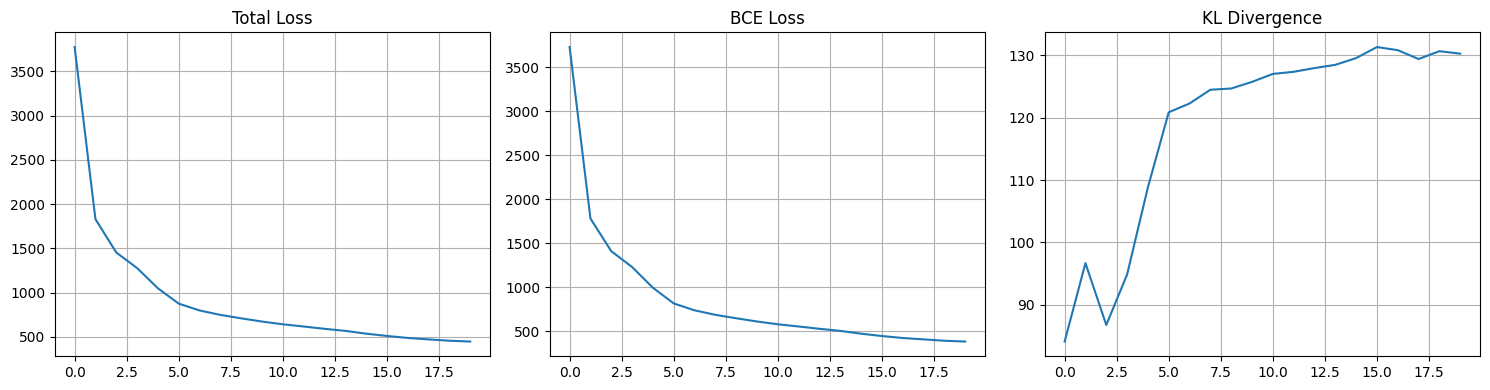


BUILDING RECOMMENDER
Building latent database...


Encoding images: 100%|██████████| 40/40 [01:36<00:00,  2.42s/it]


✓ Database built with 5000 images
✓ Nearest Neighbors model fitted
✓ Recommender saved to /kaggle/working/models/recommender.pkl

GENERATING RECOMMENDATIONS
✓ Visualization saved to /kaggle/working/results/recommendation_1.png


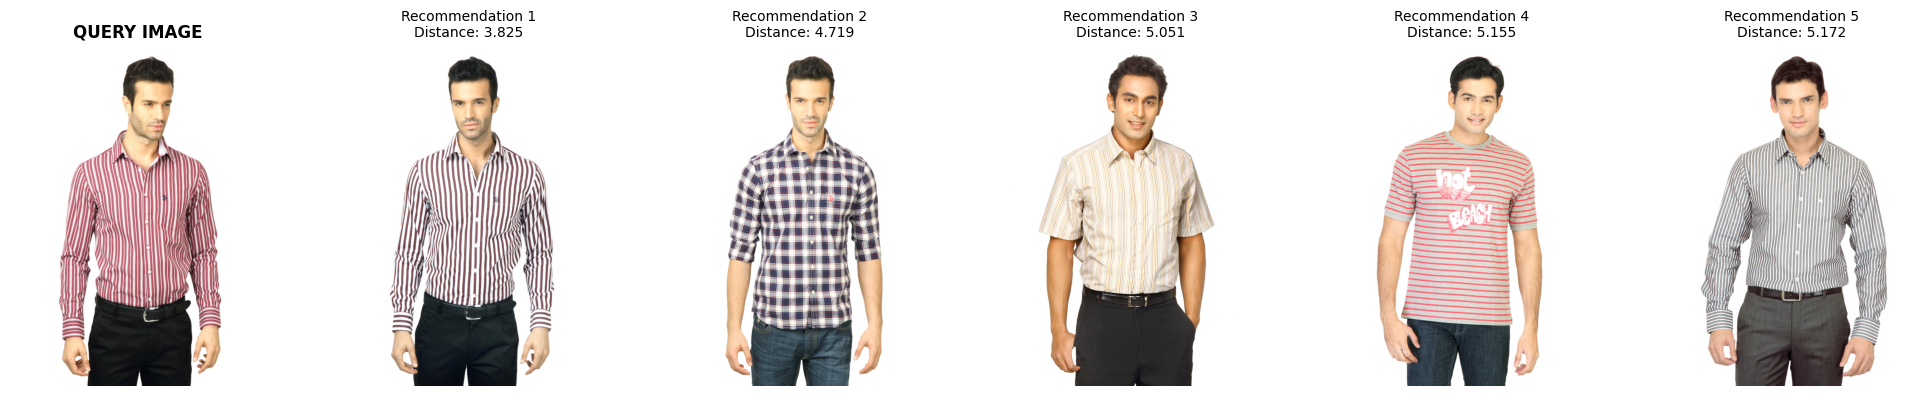

✓ Visualization saved to /kaggle/working/results/recommendation_2.png


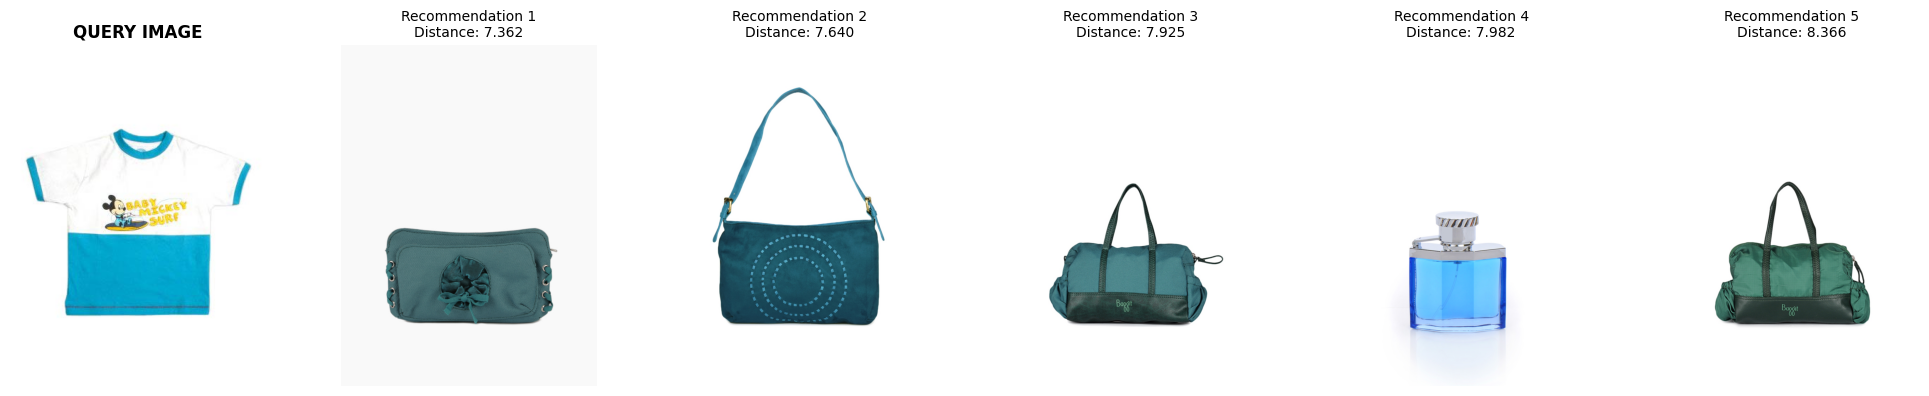

✓ Visualization saved to /kaggle/working/results/recommendation_3.png


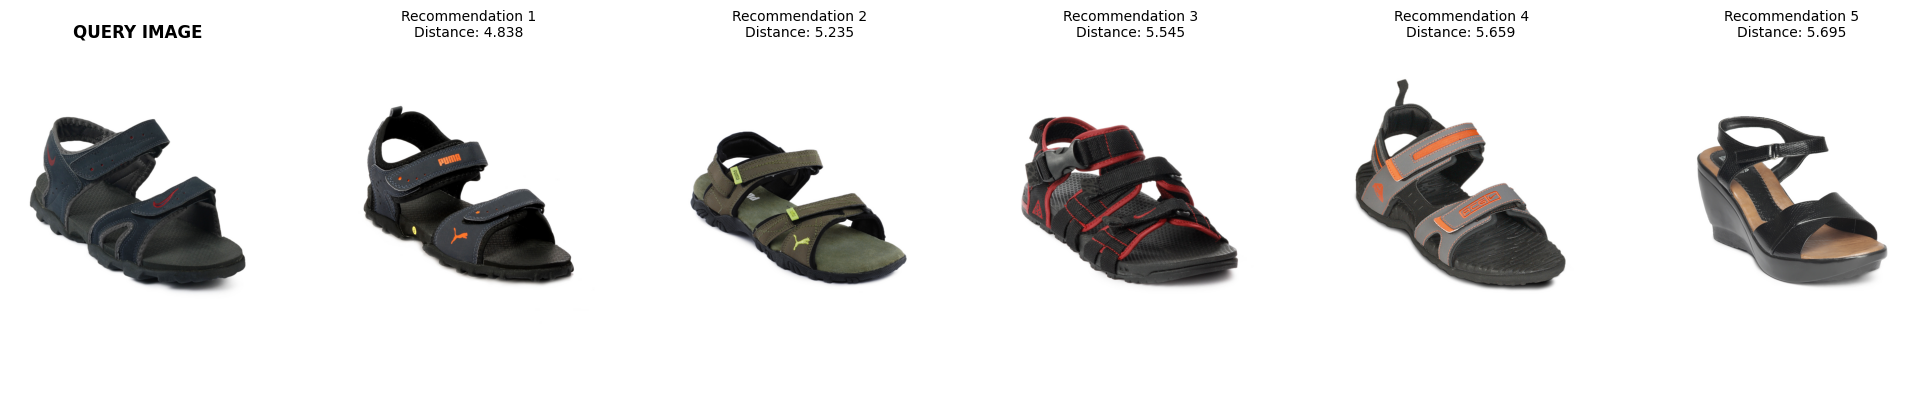


✓ PROJECT COMPLETED SUCCESSFULLY!

Output files in: /kaggle/working/
  - models/vae_final.pth
  - models/recommender.pkl
  - results/*.png


In [10]:
# ============================================
# KAGGLE COMPLETE EXECUTION
# ============================================

print("="*60)
print("FASHION VAE RECOMMENDATION SYSTEM - KAGGLE")
print("="*60)

# 1. Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n✓ Using device: {device}")

# 2. Transform
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

# 3. Dataset - İlk önce küçük subset ile test et
print("\n" + "="*60)
print("LOADING DATASET")
print("="*60)
dataset = FashionDataset(IMAGE_DIR, transform=transform, max_images=5000)

# 4. Dataloader
dataloader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# 5. Model
print("\n" + "="*60)
print("INITIALIZING MODEL")
print("="*60)
model = VAE(image_size=64, latent_dim=128).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"✓ Total parameters: {total_params:,}")

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

# 6. Training
print("\n" + "="*60)
print("STARTING TRAINING")
print("="*60)
# Eski:
# history = train_vae_kaggle(model, dataloader, optimizer, device, num_epochs=20, kl_weight=0.5)

# Yeni - Basit versiyon:
history = train_vae_simple(model, dataloader, optimizer, device, num_epochs=20, kl_weight=0.5)
# 7. Save final model
final_model_path = os.path.join(MODEL_DIR, 'vae_final.pth')
torch.save(model.state_dict(), final_model_path)
print(f"\n✓ Final model saved: {final_model_path}")

# 8. Plot training
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(history['total_loss'])
axes[0].set_title('Total Loss')
axes[0].grid(True)

axes[1].plot(history['bce'])
axes[1].set_title('BCE Loss')
axes[1].grid(True)

axes[2].plot(history['kld'])
axes[2].set_title('KL Divergence')
axes[2].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'training_history.png'), dpi=150)
plt.show()

# 9. Build recommender
print("\n" + "="*60)
print("BUILDING RECOMMENDER")
print("="*60)
eval_dataloader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=2)
recommender = FashionRecommender(model, device)
recommender.build_latent_database(eval_dataloader)

# 10. Save recommender
recommender_path = os.path.join(MODEL_DIR, 'recommender.pkl')
recommender.save(recommender_path)

# 11. Test recommendations
print("\n" + "="*60)
print("GENERATING RECOMMENDATIONS")
print("="*60)
for i in range(3):
    query_idx = np.random.randint(0, len(recommender.image_names))
    save_path = os.path.join(RESULTS_DIR, f'recommendation_{i+1}.png')
    visualize_recommendations_kaggle(recommender, query_idx, IMAGE_DIR, save_path)

print("\n" + "="*60)
print("✓ PROJECT COMPLETED SUCCESSFULLY!")
print("="*60)
print(f"\nOutput files in: {WORKING_DIR}")
print(f"  - models/vae_final.pth")
print(f"  - models/recommender.pkl")
print(f"  - results/*.png")